# Nutrition5k: resultados de los híbridos móviles

No entrena nada: lee los runs de `outputs/hybrid_mobile/` (los escribe `experiments.ipynb` de esta carpeta) con las
funciones de `src/nutrition5k/results.py`. Elegir siempre por **validación** (`val_mean_pmae`); test se informa pero no
decide. `test_clean_mean_pmae` es el test oficial sin los platos de `data/nutrition5k/excluded_dishes.csv`.

La pareja `v4m` ↔ `v4hm` (Q2a) se compara en `notebooks/results_general.ipynb` o cargando también `mobilenet`.

In [1]:
import os
from pathlib import Path

if Path("/workspace").is_dir():  # RunPod
    # The clone made by experiments.ipynb: outputs/ links to the volume and data/ holds the frames.
    os.chdir("/root/thesis-multimodal-health-ai")
elif Path.cwd().parent.name == "notebooks":
    os.chdir("../..")

import pandas as pd

from nutrition5k.results import (
    baseline_row, compare, cost, gallery, load_runs, seed_files, seed_groups, seed_spread, seed_table,
    seed_targets, select, steps, target_curves, target_table, test_metrics,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

FAMILY = "hybrid_mobile"
SPLIT = "pilot"         # "full" o "pilot"
MODE = "complete"      # modo de frames a comparar

all_runs = load_runs([FAMILY], SPLIT, MODE)
assert len(all_runs), f"no runs of {FAMILY} in {SPLIT}; train them with experiments.ipynb"
runs = select(all_runs)  # the recipe of the current runs; all_runs keeps every recipe
BASELINE = baseline_row(SPLIT)
print(f"{len(all_runs)} runs ({len(runs)} with the current recipe); baseline mean PMAE: "
      f"val {BASELINE['val_mean_pmae'].iloc[0]}, test {BASELINE['test_mean_pmae'].iloc[0]}")
runs

3 runs (3 with the current recipe); baseline mean PMAE: val 68.78185594884593, test 55.11396595533928


,run,path,family,backbone,recipe,unfreeze,heads,hidden,image_size,backbone_lr,seed,params_M,trainable_M,epochs_done,best_epoch,sec_per_epoch,gpu,gpu_memory_gb,status,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,val_total_mass_pmae,val_total_mass_mae,val_total_mass_rmse,val_total_mass_rsquared,val_total_calories_pmae,val_total_calories_mae,val_total_calories_rmse,val_total_calories_rsquared,val_total_fat_pmae,val_total_fat_mae,val_total_fat_rmse,val_total_fat_rsquared,val_total_carb_pmae,val_total_carb_mae,val_total_carb_rmse,val_total_carb_rsquared,val_total_protein_pmae,val_total_protein_mae,val_total_protein_rmse,val_total_protein_rsquared,test_total_mass_pmae,test_total_mass_mae,test_total_mass_rmse,test_total_mass_rsquared,test_total_calories_pmae,test_total_calories_mae,test_total_calories_rmse,test_total_calories_rsquared,test_total_fat_pmae,test_total_fat_mae,test_total_fat_rmse,test_total_fat_rsquared,test_total_carb_pmae,test_total_carb_mae,test_total_carb_rmse,test_total_carb_rsquared,test_total_protein_pmae,test_total_protein_mae,test_total_protein_rmse,test_total_protein_rsquared
1,fastvit_sa12-ft_all-single-h512-224-complete-p...,outputs/hybrid_mobile/pilot/fastvit_sa12/fastv...,hybrid_mobile,fastvit_sa12,fbn+clean,all,single,512,224,0.0001,0,11.213381,11.213381,3,2,13.386962,None,NaN,done,62.313713,59.920053,59.920053,54.400731,180.791763,216.325752,-0.100993,26.753774,69.103365,113.421909,0.381210,110.884418,16.982024,17.142773,0.105773,52.077774,8.342032,9.587942,-1.212356,67.451868,20.644602,21.394688,-0.101754,75.577705,87.008833,95.759686,-3.833626,41.268146,112.747787,129.950681,0.299778,67.492047,12.741191,13.983287,0.173929,72.394246,9.807284,11.887151,-2.004446,42.868121,6.156985,8.418545,0.187780
0,fastvit_s12-ft_all-single-h512-224-complete-pi...,outputs/hybrid_mobile/pilot/fastvit_s12/fastvi...,hybrid_mobile,fastvit_s12,fbn+clean,all,single,512,224,0.0001,0,9.105989,9.105989,3,2,13.255876,None,NaN,done,65.991491,64.356435,64.356435,58.996274,196.064285,238.008816,-0.332766,38.149322,98.537371,133.918994,0.137352,96.412138,14.765584,16.976376,0.123049,55.065203,8.820571,9.542865,-1.191603,81.334518,24.893585,27.514608,-0.822214,72.819695,83.833673,89.734791,-3.244527,51.393762,140.411758,161.281229,-0.078565,75.875796,14.323881,17.241862,-0.255935,63.249301,8.568414,10.363617,-1.283660,58.443622,8.394035,9.913264,-0.126246
2,v4hm-ft_all-single-h512-224-complete-pilot-fbn...,outputs/hybrid_mobile/pilot/v4hm/v4hm-ft_all-s...,hybrid_mobile,v4hm,fbn+clean,all,single,512,224,0.0001,0,10.582133,10.582133,3,1,9.982857,None,NaN,done,66.654786,66.064325,66.064325,59.486294,197.692785,226.604812,-0.208109,48.728133,125.861794,139.217468,0.067741,101.500118,15.544812,18.044802,0.009192,38.004721,6.087753,6.276135,0.052042,85.554665,26.185221,29.684544,-1.120964,105.519558,121.479391,129.414280,-7.828197,48.370389,132.151667,145.262655,0.125043,74.422490,14.049525,16.552548,-0.157520,41.184362,5.579266,8.157356,-0.414841,60.824827,8.736038,10.091170,-0.167032


## Etapa 1 (L1): arquitecturas (fine-tuning completo, cabeza `single`, 512, 224 px, lr del backbone 1e-4, semilla 0)

Resumen (`best_epoch` es la época con el menor `val_mean_pmae`, la que se guarda en `best.pt` y se evalúa), tabla de
validación con PMAE, MAE, RMSE y R² por objetivo (en verde el mejor de cada columna; MAE y RMSE en g o kcal), PMAE por
objetivo en barras y curvas de validación (el círculo grande marca la mejor época). La fila `baseline` es la línea
base de la media (predice la media de train para todos los platos) sobre la misma validación.

,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,model
1,fastvit_sa12-ft_all-single-h512-224-complete-p...,done,3.0,2.0,62.313713,59.920053,59.920053,11.213381,11.213381,13.386962,fastvit_sa12 ft all
0,fastvit_s12-ft_all-single-h512-224-complete-pi...,done,3.0,2.0,65.991491,64.356435,64.356435,9.105989,9.105989,13.255876,fastvit_s12 ft all
2,v4hm-ft_all-single-h512-224-complete-pilot-fbn...,done,3.0,1.0,66.654786,66.064325,66.064325,10.582133,10.582133,9.982857,v4hm ft all
0,average baseline,done,NaN,NaN,68.781856,55.113966,55.113966,0.000000,0.000000,NaN,baseline


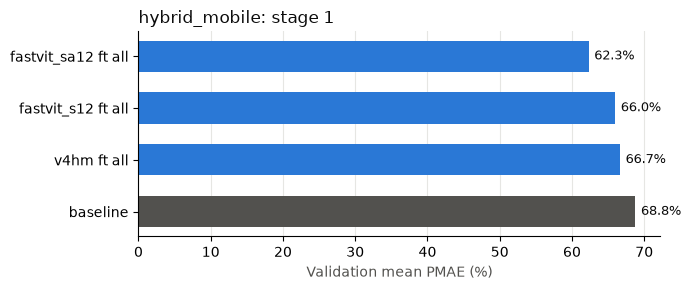

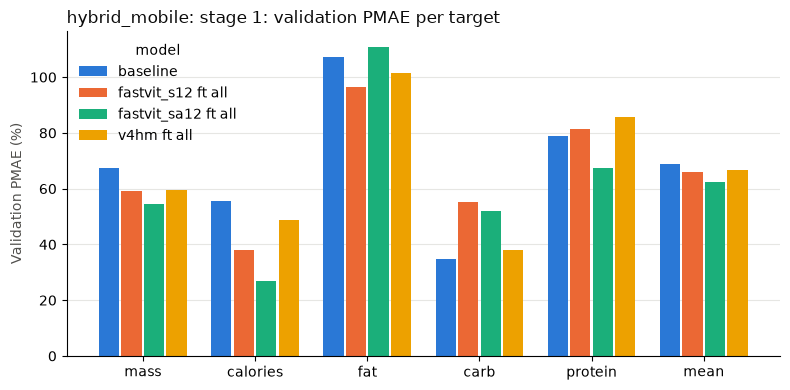

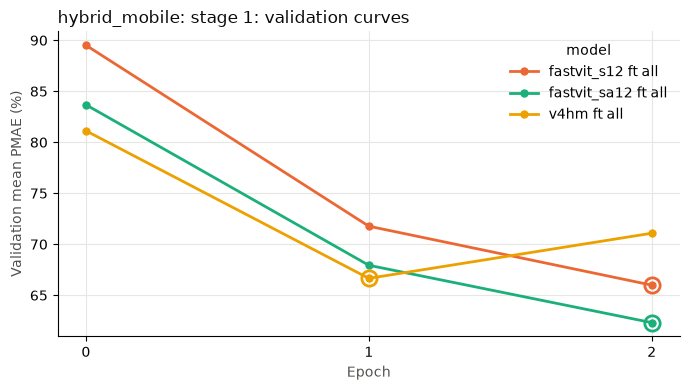

In [2]:
STAGE1 = dict(heads="single", hidden="512", image_size=224, backbone_lr=1e-4, seed=0)
stage1 = select(runs, unfreeze="all", **STAGE1)
stage1 = stage1.assign(model=stage1["backbone"] + " ft " + stage1["unfreeze"])
compare(stage1, "model", f"{FAMILY}: stage 1", baseline=BASELINE)

### Etapa 1: coste computacional

- `params_M`: parámetros en millones (backbone, tronco y cabezas). `size_MB`: tamaño de `best.pt` (float32).
- `MMACs`: millones de multiplicaciones-acumulaciones por imagen a la resolución del run; no depende del hardware.
- `cpu_ms`: latencia mediana de una imagen (batch 1) en la CPU de esta máquina, con pesos aleatorios. Solo compara
  backbones entre sí en la misma máquina; la latencia que cuenta es la del dispositivo.
- `gpu_memory_gb` y `sec_per_epoch`: pico de memoria de GPU y segundos por época **del entrenamiento**.

/home/abello/Desktop/harness-thesis-multimodal-health-ai/code/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


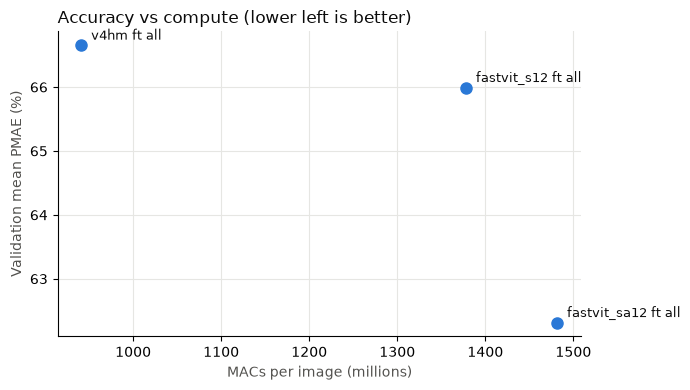

,family,val_mean_pmae,params_M,size_MB,MMACs,cpu_ms,gpu_memory_gb,sec_per_epoch,gpu
model,,,,,,,,,
fastvit_sa12 ft all,hybrid_mobile,62.313713,11.213381,45.169473,1481.807616,35.540075,NaN,13.386962,None
fastvit_s12 ft all,hybrid_mobile,65.991491,9.105989,36.774463,1378.319616,32.041059,NaN,13.255876,None
v4hm ft all,hybrid_mobile,66.654786,10.582133,42.833089,941.232832,24.716450,NaN,9.982857,None


In [3]:
cost(stage1, "model")

## Etapa 2 (L2): ablaciones

Cada finalista sigue su propio camino greedy (mismos `BACKBONES` y `BEST_*` que en `experiments.ipynb`).
Cada paso compara el valor del factor dentro del backbone; menos de ~1 punto es empate.

In [4]:
BACKBONES = ("fastvit_sa12",)
BEST_UNFREEZE = {"fastvit_sa12": "2"}  # como texto, igual que en experiments.ipynb

for backbone in BACKBONES:
    steps(runs, backbone, {
        "Step 1: fine-tuning depth": ("unfreeze", dict(heads="single", hidden="512", backbone_lr=1e-4, seed=0)),
        "Step 2: backbone learning rate": ("backbone_lr", dict(unfreeze=BEST_UNFREEZE[backbone], heads="single", hidden="512", seed=0)),
    })

fastvit_sa12 - Step 1: fine-tuning depth
  nothing to compare yet
fastvit_sa12 - Step 2: backbone learning rate
  nothing to compare yet


## Error por objetivo (test) de todas las ejecuciones terminadas

Ordenadas por validación. Solo se informa: no sirve para elegir.

In [5]:
target_table(runs[runs["status"] == "done"], "run", split="test")

## Evolución por objetivo de una ejecución

Comprueba si un objetivo empeora mientras la media mejora. La línea negra es la media; la vertical marca la época elegida.

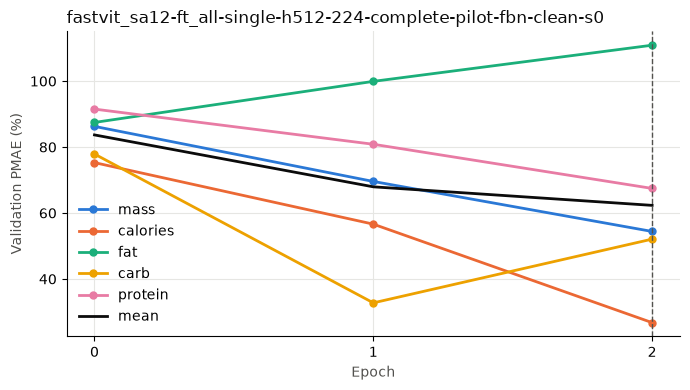

In [6]:
BEST = runs[runs["status"] == "done"].iloc[0]  # el mejor por validación; o all_runs[all_runs["run"] == "<nombre>"].iloc[0]
target_curves(BEST["path"])

## Etapa 3 (L3): media ± SD entre semillas

Una fila por configuración con más de una semilla; gráficas con el error de cada semilla (puntos) y la media ± SD.

In [7]:
seed_runs = seed_groups(runs)
if len(seed_runs):
    display(seed_table(seed_runs))
    seed_spread(seed_runs)
    seed_targets(seed_runs, "val")
    seed_targets(seed_runs, "test")
else:
    print("no configuration with more than one seed yet")

no configuration with more than one seed yet


## Métricas de test de los modelos finales

MAE, PMAE, RMSE y R² por objetivo, con la línea base como referencia. Por defecto, los tres mejores runs por
validación. Debajo, la media ± SD que escribe `train --all-seeds`.

In [8]:
FINAL = runs[runs["status"] == "done"].head(3)  # o select(runs, backbone=..., unfreeze=...)
test_metrics(FINAL, SPLIT).round(2)

unit     MAE  PMAE (%)    RMSE    R²
model                                              target                                        
fastvit_sa12-ft_all-single-h512-224-complete-pi... mass         g   87.01     75.58   95.76 -3.83
                                                   calories  kcal  112.75     41.27  129.95  0.30
                                                   fat          g   12.74     67.49   13.98  0.17
                                                   carb         g    9.81     72.39   11.89 -2.00
                                                   protein      g    6.16     42.87    8.42  0.19
                                                   mean       NaN     NaN     59.92     NaN   NaN
fastvit_s12-ft_all-single-h512-224-complete-pil... mass         g   83.83     72.82   89.73 -3.24
                                                   calories  kcal  140.41     51.39  161.28 -0.08
                                                   fat          g   14.32     75.88   17.24 -0.26
                                                   carb         g    8.57     63.25   10.36 -1.28
                                                   protein      g    8.39     58.44    9.91 -0.13
                                                   mean       NaN     NaN     64.36     NaN   NaN
v4hm-ft_all-single-h512-224-complete-pilot-fbn-... mass         g  121.48    105.52  129.41 -7.83
                                                   calories  kcal  132.15     48.37  145.26  0.13
                                                   fat          g   14.05     74.42   16.55 -0.16
                                                   carb         g    5.58     41.18    8.16 -0.41
                                                   protein      g    8.74     60.82   10.09 -0.17
                                                   mean       NaN     NaN     66.06     NaN   NaN
average baseline                                   mass         g   67.98     59.05   79.36 -2.32
                                                   calories  kcal  143.70     52.60  159.45 -0.05
                                                   fat          g   14.16     74.99   16.25 -0.12
                                                   carb         g    5.13     37.83    7.06 -0.06
                                                   protein      g    7.34     51.10    9.73 -0.09
                                                   mean       NaN     NaN     55.11     NaN   NaN

In [9]:
seed_files(FAMILY, SPLIT, MODE)

""


## Galería de platos de test

Los platos con menor error, los de mayor error y algunos al azar de un run, con su primer frame, el valor real y
el predicho. Necesita los frames en `data/`.

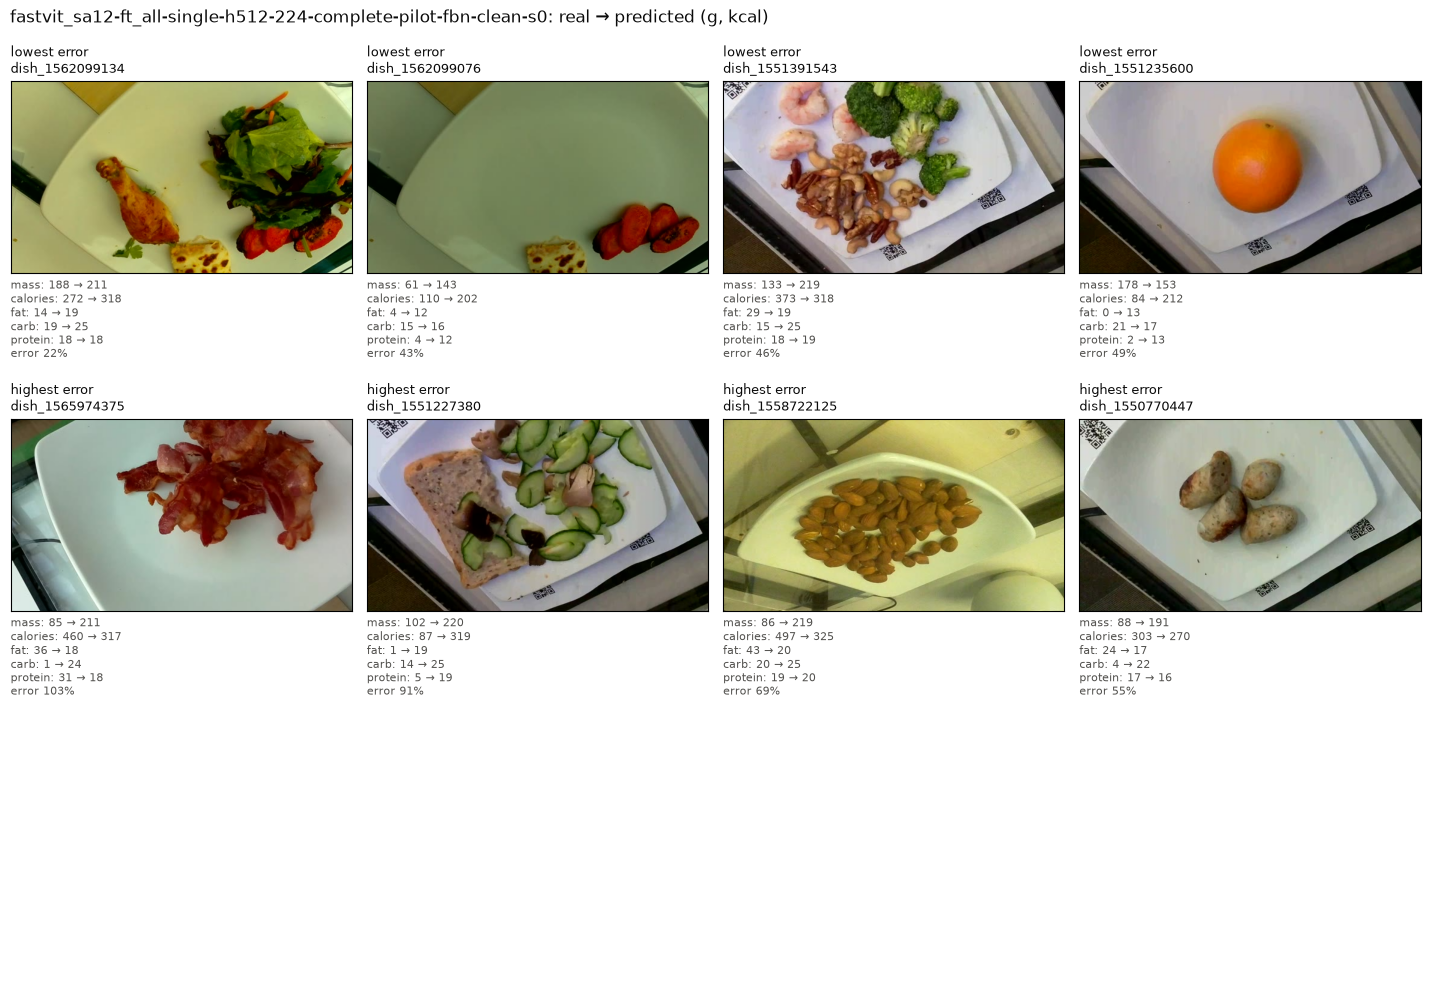

In [10]:
gallery(BEST["path"], SPLIT, MODE)